# Pareja C — Métricas, prueba estadística y análisis de errores

## 3.0 Alcance

Este notebook cubre **exclusivamente el eje de trabajo de la pareja C**:

- integrar en un solo flujo la línea base de la pareja A y los resultados de la pareja B, **sin modificar** sus notebooks ni sus archivos;
- matrices de confusión comparativas y curvas ROC con su AUC;
- prueba de hipótesis emparejada entre los dos modelos;
- identificación de los billetes mal clasificados (falsos positivos frente a falsos negativos);
- efecto de los 24 registros duplicados (decisión del equipo: **medirlo y reportarlo**, no eliminarlos).

### Protocolo heredado (no se cambia)

| Elemento | Valor |
|---|---|
| Semilla | `random_state=42` |
| Partición train/test | 80 % / 20 %, estratificada |
| Validación externa | `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` sobre `X_train` |
| Métrica principal | recall de la clase falsa (`1`) — **sin cambios** |
| Métricas complementarias de A y B | accuracy, precision (falso), F1 (falso) |
| Clase positiva | `1` = billete **falso**; `0` = genuino |

Con esta convención, un **falso negativo (FN)** es una falsificación aceptada como genuina (el error costoso) y un **falso positivo (FP)** es un billete genuino rechazado (revisión adicional).

El enunciado de la práctica describe los errores en lenguaje de negocio ("aceptar una falsificación", "rechazar un genuino"). En este trabajo se declara de forma explícita que la clase positiva es `is_fake = 1` y que todas las métricas se calculan con esa convención.

El conjunto `X_test` se usa **una sola vez**, en la sección 3.6, y nada se ajusta con él.

# 3.1 Entorno, constantes y versiones de software

Las constantes (`FEATURES`, `TARGET`, `RANDOM_STATE`, paleta de colores y carpeta de figuras) son **idénticas** a las de A y B. Las versiones de software se imprimen y se guardan para poder reproducir el experimento.

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from scipy import stats
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# --- Constantes IDÉNTICAS a las de las parejas A y B (no cambiar sin avisar) ---
FEATURES = ['variance', 'skewness', 'kurtosis', 'entropy']
TARGET = 'is_fake'
RANDOM_STATE = 42
PLOTS_DIR = Path('../report/plots')
RESULTS_B_DIR = Path('../p_02')
RESULTS_DIR = Path('../results/pareja_c')
PLOTS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

blues = plt.get_cmap('Blues')
corals = plt.get_cmap('RdPu')
COLORS = {0: blues(0.72), 1: corals(0.72)}
CLASS_LABELS = {0: 'Genuino (0)', 1: 'Falso (1)'}

# Mismos colores que A y B usaron para sus barras de resultados.
MODEL_LR, MODEL_RF = 'Regresión logística', 'Random Forest'
MODEL_COLORS = {MODEL_LR: blues(0.68), MODEL_RF: corals(0.68)}

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'figure.figsize': (10, 6),
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'axes.titlesize': 13,
    'figure.dpi': 110,
})

versions = {
    'python': sys.version.split()[0],
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'scipy': scipy.__version__,
    'scikit-learn': sklearn.__version__,
    'matplotlib': matplotlib.__version__,
    'joblib': joblib.__version__,
}
for name, version in versions.items():
    print(f'{name:>13}: {version}')

       python: 3.13.14
        numpy: 2.5.4
       pandas: 3.1.0
        scipy: 1.18.1
 scikit-learn: 1.9.1
   matplotlib: 3.11.2
       joblib: 1.6.0


# 3.2 Datos y partición (idéntica a A y B)

Se repite **exactamente** la misma llamada a `train_test_split` (`test_size=0.20`, `stratify=y`, `random_state=42`) sobre el mismo archivo, de modo que las filas de entrenamiento y de prueba son las mismas que usaron A y B. Las aserciones comprueban que el resultado coincide con lo que ellas reportaron (1,097 / 275 filas; 0.445 y 0.444 de falsos).

In [2]:
data_path = Path('../p_02/data_banknote_authentication.txt')
if not data_path.exists():
    raise FileNotFoundError(f'No se encontró el dataset en: {data_path.resolve()}')

df = pd.read_csv(data_path, header=None, names=FEATURES + [TARGET])
df[TARGET] = pd.to_numeric(df[TARGET], errors='raise').astype(int)

X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

assert (len(df), len(X_train), len(X_test)) == (1372, 1097, 275)
assert round(y_train.mean(), 3) == 0.445 and round(y_test.mean(), 3) == 0.444

print(f'Train: {len(X_train):,} | Test (se usa una sola vez, en 3.6): {len(X_test):,}')
print(f'Proporción de falsos en train: {y_train.mean():.3f} | en test: {y_test.mean():.3f}')

Train: 1,097 | Test (se usa una sola vez, en 3.6): 275
Proporción de falsos en train: 0.445 | en test: 0.444


# 3.3 Línea base de la pareja A, reproducida

La pareja A no guardó en disco sus predicciones por pliegue ni su modelo final (solo aparecen en la salida de su notebook). Para no tocar su archivo, aquí se **vuelve a ejecutar su mismo procedimiento**: el mismo `Pipeline` (`StandardScaler` + `LogisticRegression(solver='lbfgs', max_iter=2000, random_state=42)`) y el mismo `StratifiedKFold`. El escalador se ajusta de nuevo en cada pliegue solo con su entrenamiento, así que no hay fuga de información.

Como control, se compara la reproducción con la tabla que A publicó (accuracy, precision, recall y F1 de cada pliegue, y los coeficientes del modelo final). Si algo no coincidiera, el notebook se detiene.

In [3]:
METRIC_NAMES = ['accuracy', 'precision_fake', 'recall_fake', 'f1_fake']


def fold_metrics(y_true, y_pred):
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision_fake': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        'recall_fake': recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        'f1_fake': f1_score(y_true, y_pred, pos_label=1, zero_division=0),
    }


# Mismo esquema externo que A y B; las posiciones de cada pliegue se guardan para reutilizarlas.
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(outer_cv.split(X_train, y_train))

logistic_pipeline = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(solver='lbfgs', max_iter=2_000, random_state=RANDOM_STATE)),
])

lr_rows, lr_oof_rows = [], []
for fold, (idx_tr, idx_val) in enumerate(folds, start=1):
    pipe = clone(logistic_pipeline)
    pipe.fit(X_train.iloc[idx_tr], y_train.iloc[idx_tr])      # solo el entrenamiento del pliegue
    X_val, y_val = X_train.iloc[idx_val], y_train.iloc[idx_val]
    pred = pipe.predict(X_val)
    proba = pipe.predict_proba(X_val)[:, 1]
    lr_rows.append({'fold': fold, **fold_metrics(y_val, pred)})
    lr_oof_rows.append(pd.DataFrame({
        'fold': fold, 'index': X_val.index, 'y_true': y_val.to_numpy(),
        'y_pred_lr': pred, 'proba_lr': proba,
    }))

fold_scores_lr = pd.DataFrame(lr_rows).set_index('fold')
lr_oof = pd.concat(lr_oof_rows, ignore_index=True)

# --- Control contra la tabla publicada por la pareja A (valores tal como aparecen en su notebook) ---
A_PUBLICADO = pd.DataFrame({
    'accuracy':       [0.9773, 0.9864, 0.9863, 0.9772, 0.9954],
    'precision_fake': [0.9515, 0.9798, 0.9703, 0.9600, 0.9898],
    'recall_fake':    [1.0000, 0.9898, 1.0000, 0.9897, 1.0000],
    'f1_fake':        [0.9751, 0.9848, 0.9849, 0.9746, 0.9949],
}, index=pd.RangeIndex(1, 6, name='fold'))
pd.testing.assert_frame_equal(fold_scores_lr.round(4), A_PUBLICADO, check_exact=False, atol=1.1e-4)

# Modelo final de A: se ajusta con todo X_train (igual que su sección 1.14).
logistic_final = clone(logistic_pipeline).fit(X_train, y_train)
coef_final = pd.Series(logistic_final.named_steps['model'].coef_[0], index=FEATURES)
A_COEF = pd.Series({'skewness': -4.8065, 'variance': -4.6660, 'kurtosis': -4.3989, 'entropy': 0.2580})
assert np.allclose(coef_final[A_COEF.index], A_COEF, atol=1e-3)
assert abs(logistic_final.named_steps['model'].intercept_[0] - (-1.3999)) < 1e-3

print('Reproducción de A: coincide con su tabla por pliegue y con sus coeficientes finales.')
display(fold_scores_lr.round(4))

Reproducción de A: coincide con su tabla por pliegue y con sus coeficientes finales.


,accuracy,precision_fake,recall_fake,f1_fake
fold,,,,
1,0.9773,0.9515,1.0000,0.9751
2,0.9864,0.9798,0.9898,0.9848
3,0.9863,0.9703,1.0000,0.9849
4,0.9772,0.9600,0.9897,0.9746
5,0.9954,0.9898,1.0000,0.9949


# 3.4 Resultados de la pareja B (cargados, sin recalcular)

Se leen los archivos que B dejó en `../results/pareja_b/`: métricas por pliegue, predicciones fuera de muestra, hiperparámetros finales y el modelo final (`.joblib`). Antes de usarlos se comprueba que:

1. los billetes de validación de cada pliegue de B son **los mismos** que los de los pliegues de A (condición para comparar pliegue contra pliegue);
2. las etiquetas reales de sus predicciones coinciden con el dataset;
3. su recall por pliegue recalculado a partir de sus predicciones coincide con su tabla;
4. el modelo `.joblib` tiene los hiperparámetros finales que B reportó.

> El archivo `.joblib` es un `pickle`: solo se carga porque proviene del propio equipo, y requiere una versión compatible de scikit-learn (ver 3.1).

In [4]:
rf_folds = pd.read_csv(RESULTS_B_DIR / '02_rf_mediciones_por_pliegue.csv', index_col='fold')
rf_oof = pd.read_csv(RESULTS_B_DIR / '03_rf_predicciones_fuera_de_muestra.csv')
rf_params = json.loads((RESULTS_B_DIR / '05_rf_hiperparametros_finales.json').read_text(encoding='utf-8'))
rf_final = joblib.load(RESULTS_B_DIR / '06_modelo_rf_final.joblib')

for fold, (idx_tr, idx_val) in enumerate(folds, start=1):
    sub = rf_oof[rf_oof['fold'] == fold]
    # 1) mismos billetes de validación que en los pliegues de A
    assert set(sub['index']) == set(X_train.index[idx_val]), f'Pliegue {fold}: billetes distintos'
    # 2) etiquetas reales coherentes con el dataset
    assert (y.loc[sub['index']].to_numpy() == sub['y_true'].to_numpy()).all()
    # 3) recall recalculado == recall reportado por B
    assert np.isclose(recall_score(sub['y_true'], sub['y_pred'], pos_label=1), rf_folds.loc[fold, 'recall_fake'])
# 4) hiperparámetros del modelo guardado == hiperparámetros reportados
assert all(rf_final.get_params()[k] == v for k, v in rf_params.items())

print('Pliegues de B == pliegues de A; predicciones y modelo final de B verificados.')
print('Hiperparámetros finales de B:', rf_params)
display(rf_folds[METRIC_NAMES].round(4))

Pliegues de B == pliegues de A; predicciones y modelo final de B verificados.
Hiperparámetros finales de B: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}


,accuracy,precision_fake,recall_fake,f1_fake
fold,,,,
1,0.9909,0.9800,1.0000,0.9899
2,1.0000,1.0000,1.0000,1.0000
3,0.9726,0.9510,0.9898,0.9700
4,1.0000,1.0000,1.0000,1.0000
5,0.9817,0.9697,0.9897,0.9796


### Tabla pareada por pliegue y predicciones fuera de muestra

Cada fila es un pliegue: las dos columnas de un mismo pliegue se evalúan sobre **los mismos billetes**, por lo que los resultados son **pareados**. Esta tabla es la que consume la prueba estadística (3.9).

Las predicciones fuera de muestra (*out-of-fold*, OOF) son las de cada billete de `X_train` cuando le tocó ser validación: cada billete se predice una vez con un modelo que no lo vio entrenar. Con ellas se construyen la matriz de confusión, la ROC y el análisis de errores de la validación cruzada.

In [5]:
paired = pd.concat(
    [fold_scores_lr.add_suffix('_lr'), rf_folds[METRIC_NAMES].add_suffix('_rf')], axis=1
)
paired = paired[[f'{m}_{s}' for m in METRIC_NAMES for s in ('lr', 'rf')]]

oof = lr_oof.merge(
    rf_oof.rename(columns={'y_pred': 'y_pred_rf', 'proba_fake': 'proba_rf', 'y_true': 'y_true_rf'}),
    on=['fold', 'index'], validate='one_to_one',
)
assert (oof['y_true'] == oof['y_true_rf']).all()
oof = oof.drop(columns='y_true_rf')
assert len(oof) == len(X_train)

display(paired.round(4))

,accuracy_lr,accuracy_rf,precision_fake_lr,precision_fake_rf,recall_fake_lr,recall_fake_rf,f1_fake_lr,f1_fake_rf
fold,,,,,,,,
1,0.9773,0.9909,0.9515,0.9800,1.0000,1.0000,0.9751,0.9899
2,0.9864,1.0000,0.9798,1.0000,0.9898,1.0000,0.9848,1.0000
3,0.9863,0.9726,0.9703,0.9510,1.0000,0.9898,0.9849,0.9700
4,0.9772,1.0000,0.9600,1.0000,0.9897,1.0000,0.9746,1.0000
5,0.9954,0.9817,0.9898,0.9697,1.0000,0.9897,0.9949,0.9796


# 3.5 Métricas complementarias que aporta la pareja C

La **métrica principal sigue siendo el recall de la clase falsa**. A y B ya fijaron como complementarias *precision*, *F1* y *accuracy*. La pareja C añade tres elementos, todos **complementarios** y declarados **antes** de evaluar en `X_test`:

| Métrica | Cómo se calcula | Cómo se interpreta | Qué información adicional aporta |
|---|---|---|---|
| **Especificidad** | $\dfrac{TN}{TN+FP}$ | De todos los billetes genuinos, qué proporción se reconoce como genuina. | Es el "recall" de la clase genuina: mide el costo operativo (revisiones innecesarias) que el recall de falsos no ve. |
| **Conteos TN, FP, FN, TP** | Matriz de confusión | Número absoluto de billetes en cada caso. | Con ~99 % de aciertos, las diferencias son de pocos billetes; los porcentajes ocultan cuántos casos son. |
| **AUC (área bajo la curva ROC)** | Área bajo la curva TPR vs. FPR al variar el umbral $\tau$ | Probabilidad de que un billete falso reciba una probabilidad mayor que uno genuino tomado al azar (1 = separación perfecta, 0.5 = azar). | Evalúa la **calidad de la ordenación** de las probabilidades sin depender del umbral $\tau = 0.5$ usado para el resto de las métricas. Se reporta por pliegue y agrupado. |

La curva ROC grafica, para cada umbral $\tau$, la tasa de falsos detectados (TPR = recall) contra la tasa de genuinos rechazados (FPR = 1 − especificidad).

**Convención de las tablas.** La **tabla principal** de comparación en validación cruzada reporta la media ± desviación estándar de cada métrica calculada **por pliegue** (igual que A y B) e incluye el AUC por pliegue. Las métricas "agrupadas" se calculan sobre las 1,097 predicciones OOF a la vez y se usan solo para las matrices de confusión, las curvas ROC y el análisis de errores. Las predicciones agrupadas provienen de cinco modelos distintos (uno por pliegue), no de un único modelo; por eso la curva ROC agrupada es una aproximación. La prueba estadística (3.9) usa las diferencias por pliegue.

In [6]:
def full_metrics(y_true, y_pred, y_proba):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        'n': len(y_true),
        'recall_fake': recall_score(y_true, y_pred, pos_label=1),
        'precision_fake': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        'f1_fake': f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        'accuracy': accuracy_score(y_true, y_pred),
        'specificity': tn / (tn + fp),
        'roc_auc': roc_auc_score(y_true, y_proba),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
    }


cv_metrics = pd.DataFrame({
    MODEL_LR: full_metrics(oof['y_true'], oof['y_pred_lr'], oof['proba_lr']),
    MODEL_RF: full_metrics(oof['y_true'], oof['y_pred_rf'], oof['proba_rf']),
}).T
print('Validación cruzada, métricas AGRUPADAS (1,097 predicciones OOF; se usan para matrices, ROC y errores):')
display(cv_metrics.round(4))

Validación cruzada, métricas AGRUPADAS (1,097 predicciones OOF; se usan para matrices, ROC y errores):


,n,recall_fake,precision_fake,f1_fake,accuracy,specificity,roc_auc,TN,FP,FN,TP
Regresión logística,1097.0,0.9959,0.9701,0.9828,0.9845,0.9754,0.9996,594.0,15.0,2.0,486.0
Random Forest,1097.0,0.9959,0.9798,0.9878,0.9891,0.9836,0.9998,599.0,10.0,2.0,486.0


### Tabla principal: métricas por pliegue (media ± desviación estándar)

Cada métrica se calcula **en cada pliegue** con los mismos billetes de validación para ambos modelos y después se resume con la media y la desviación estándar de los 5 pliegues, igual que en A y B. El AUC por pliegue usa las probabilidades que el modelo de ese pliegue asignó a sus billetes de validación. Como control, las métricas recalculadas aquí a partir de las predicciones OOF coinciden con las tablas por pliegue de A (reproducida) y de B.

In [7]:
PER_FOLD_COLS = ['recall_fake', 'precision_fake', 'f1_fake', 'accuracy', 'specificity', 'roc_auc', 'TN', 'FP', 'FN', 'TP']


def per_fold_table(suffix):
    rows = []
    for fold_id in sorted(oof['fold'].unique()):
        sub = oof[oof['fold'] == fold_id]
        m = full_metrics(sub['y_true'], sub[f'y_pred_{suffix}'], sub[f'proba_{suffix}'])
        rows.append({'fold': int(fold_id), **{c: m[c] for c in PER_FOLD_COLS}})
    return pd.DataFrame(rows).set_index('fold')


fold_lr_full = per_fold_table('lr')
fold_rf_full = per_fold_table('rf')

# Control: coinciden con las tablas por pliegue de A (reproducida) y de B
pd.testing.assert_frame_equal(fold_lr_full[METRIC_NAMES], fold_scores_lr[METRIC_NAMES], check_exact=False, atol=1e-9, check_dtype=False)
pd.testing.assert_frame_equal(fold_rf_full[METRIC_NAMES], rf_folds[METRIC_NAMES], check_exact=False, atol=1e-9, check_dtype=False)

folds_full = pd.concat([fold_lr_full.add_suffix('_lr'), fold_rf_full.add_suffix('_rf')], axis=1)

FULL_METRICS = ['recall_fake', 'precision_fake', 'f1_fake', 'accuracy', 'specificity', 'roc_auc']
summary_cv = pd.DataFrame({
    MODEL_LR: [f"{fold_lr_full[m].mean():.4f} ± {fold_lr_full[m].std(ddof=1):.4f}" for m in FULL_METRICS],
    MODEL_RF: [f"{fold_rf_full[m].mean():.4f} ± {fold_rf_full[m].std(ddof=1):.4f}" for m in FULL_METRICS],
}, index=pd.Index(FULL_METRICS, name='métrica'))
print('Tabla principal — validación cruzada externa, media ± desviación estándar de los 5 pliegues:')
display(summary_cv)

print('AUC por pliegue (probabilidades de validación de cada pliegue):')
display(pd.DataFrame({MODEL_LR: fold_lr_full['roc_auc'], MODEL_RF: fold_rf_full['roc_auc']}).round(5))


Tabla principal — validación cruzada externa, media ± desviación estándar de los 5 pliegues:


,Regresión logística,Random Forest
métrica,,
recall_fake,0.9959 ± 0.0056,0.9959 ± 0.0056
precision_fake,0.9703 ± 0.0153,0.9801 ± 0.0209
f1_fake,0.9829 ± 0.0084,0.9879 ± 0.0131
accuracy,0.9845 ± 0.0076,0.9890 ± 0.0119
specificity,0.9754 ± 0.0130,0.9835 ± 0.0175
roc_auc,0.9997 ± 0.0002,0.9998 ± 0.0002


AUC por pliegue (probabilidades de validación de cada pliegue):


,Regresión logística,Random Forest
fold,,
1,0.99967,0.99992
2,0.99967,1.00000
3,0.99966,0.99958
4,0.99932,1.00000
5,1.00000,0.99966


# 3.6 Evaluación final en `X_test` (una sola vez)

Los dos **modelos finales** (ajustados con todo `X_train` y sin haber visto `X_test`) se evalúan aquí por primera y única vez:

- regresión logística: el pipeline final de A, reproducido en 3.3;
- Random Forest: el modelo `06_modelo_rf_final.joblib` entregado por B.

Se usa el umbral usual $\tau = 0.5$ (`predict`). **No se elige ningún umbral, hiperparámetro ni criterio con estos resultados.**

In [8]:
pred_test_lr = logistic_final.predict(X_test)
proba_test_lr = logistic_final.predict_proba(X_test)[:, 1]
pred_test_rf = rf_final.predict(X_test)
proba_test_rf = rf_final.predict_proba(X_test)[:, 1]

test_predictions = pd.DataFrame({
    'index': X_test.index, 'y_true': y_test.to_numpy(),
    'y_pred_lr': pred_test_lr, 'proba_lr': proba_test_lr,
    'y_pred_rf': pred_test_rf, 'proba_rf': proba_test_rf,
})

test_metrics = pd.DataFrame({
    MODEL_LR: full_metrics(y_test, pred_test_lr, proba_test_lr),
    MODEL_RF: full_metrics(y_test, pred_test_rf, proba_test_rf),
}).T
print(f'Evaluación final en X_test ({len(X_test)} billetes):')
display(test_metrics.round(4))

Evaluación final en X_test (275 billetes):


,n,recall_fake,precision_fake,f1_fake,accuracy,specificity,roc_auc,TN,FP,FN,TP
Regresión logística,275.0,1.0,0.9385,0.9683,0.9709,0.9477,0.9999,145.0,8.0,0.0,122.0
Random Forest,275.0,1.0,0.9919,0.9959,0.9964,0.9935,1.0000,152.0,1.0,0.0,122.0


# 3.7 Matrices de confusión comparativas

Cada matriz cuenta los billetes por **clase real** (filas) y **clase predicha** (columnas). Para la clase positiva "falso":

- esquina inferior izquierda = **FN**: falsificación aceptada como genuina (error costoso);
- esquina superior derecha = **FP**: genuino rechazado (revisión adicional).

La fila superior muestra la validación cruzada (OOF, 1,097 billetes) y la inferior el conjunto de prueba (275 billetes).

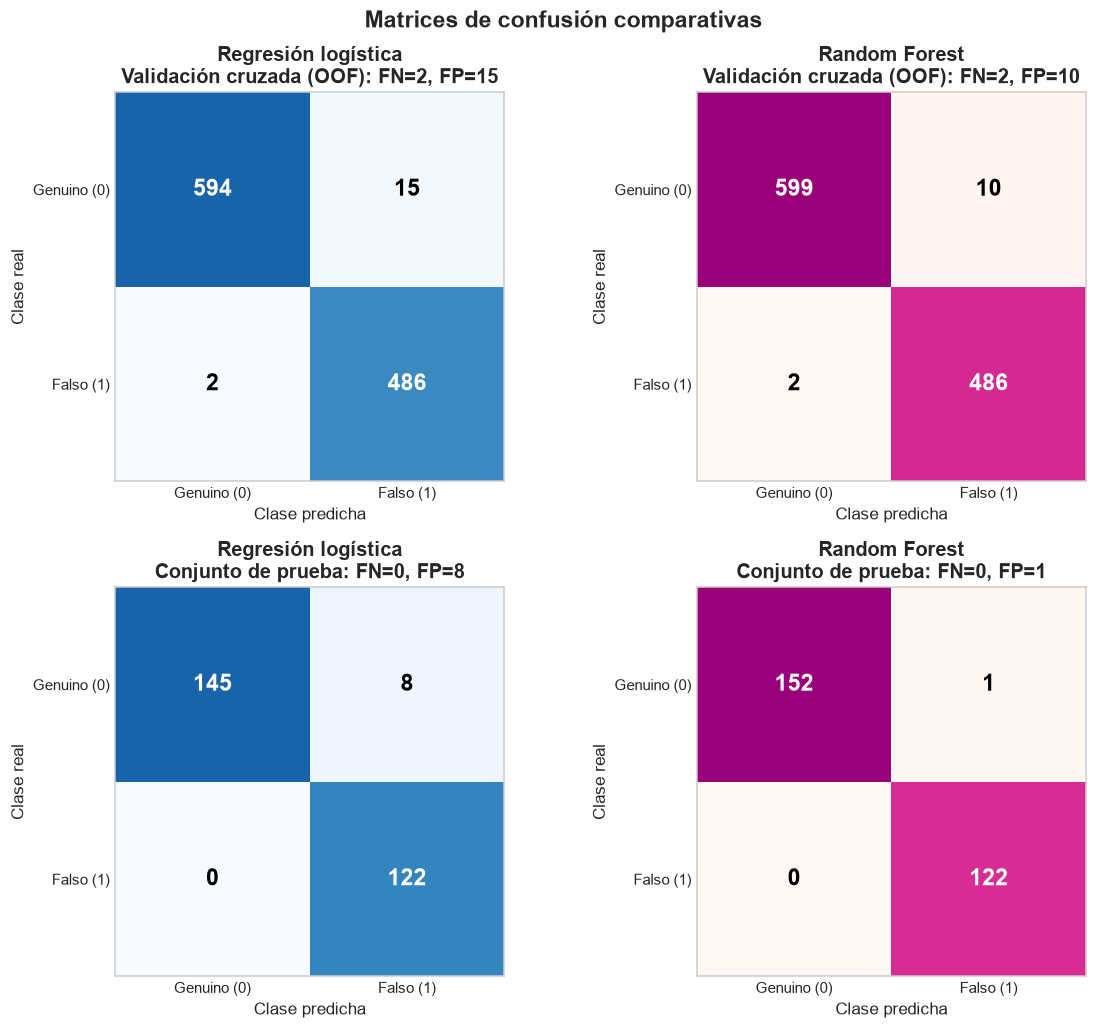

TN  FP  FN   TP
Validación cruzada (OOF) Regresión logística  594  15   2  486
                         Random Forest        599  10   2  486
Prueba                   Regresión logística  145   8   0  122
                         Random Forest        152   1   0  122

In [9]:
def draw_confusion(ax, y_true, y_pred, cmap, title):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    ax.imshow(cm, cmap=cmap, vmin=0, vmax=cm.max() * 1.25)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]:,}', ha='center', va='center', fontsize=15, fontweight='bold',
                    color='white' if cm[i, j] > cm.max() * 0.5 else 'black')
    ax.set_xticks([0, 1], ['Genuino (0)', 'Falso (1)'])
    ax.set_yticks([0, 1], ['Genuino (0)', 'Falso (1)'])
    ax.set_xlabel('Clase predicha')
    ax.set_ylabel('Clase real')
    ax.set_title(title)
    ax.grid(False)


fig, axes = plt.subplots(2, 2, figsize=(11, 9.5))
panels = [
    (axes[0, 0], oof['y_true'], oof['y_pred_lr'], 'Blues', MODEL_LR, 'Validación cruzada (OOF)'),
    (axes[0, 1], oof['y_true'], oof['y_pred_rf'], 'RdPu', MODEL_RF, 'Validación cruzada (OOF)'),
    (axes[1, 0], y_test, pred_test_lr, 'Blues', MODEL_LR, 'Conjunto de prueba'),
    (axes[1, 1], y_test, pred_test_rf, 'RdPu', MODEL_RF, 'Conjunto de prueba'),
]
for ax, yt, yp, cmap, model, subset in panels:
    tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
    draw_confusion(ax, yt, yp, cmap, f'{model}\n{subset}: FN={fn}, FP={fp}')
fig.suptitle('Matrices de confusión comparativas', fontsize=15, fontweight='bold')
plt.tight_layout()
fig.savefig(PLOTS_DIR / '11_matrices_confusion_comparativas.png', dpi=300, bbox_inches='tight')
plt.show()

counts = pd.concat({'Validación cruzada (OOF)': cv_metrics[['TN', 'FP', 'FN', 'TP']],
                    'Prueba': test_metrics[['TN', 'FP', 'FN', 'TP']]})
display(counts.astype(int))

# 3.8 Curvas ROC y AUC

Para cada billete, ambos modelos entregan la probabilidad de que sea falso. La curva ROC recorre todos los umbrales posibles; el punto marcado (●) es el umbral de decisión usado en todo el estudio, $\tau = 0.5$. Como ambas curvas quedan muy cerca de la esquina superior izquierda, la fila inferior muestra la **misma curva ampliada** en esa región.

> En la validación cruzada la curva usa las probabilidades OOF de los cinco pliegues juntas; cada pliegue viene de un modelo distinto, así que es una aproximación agrupada.

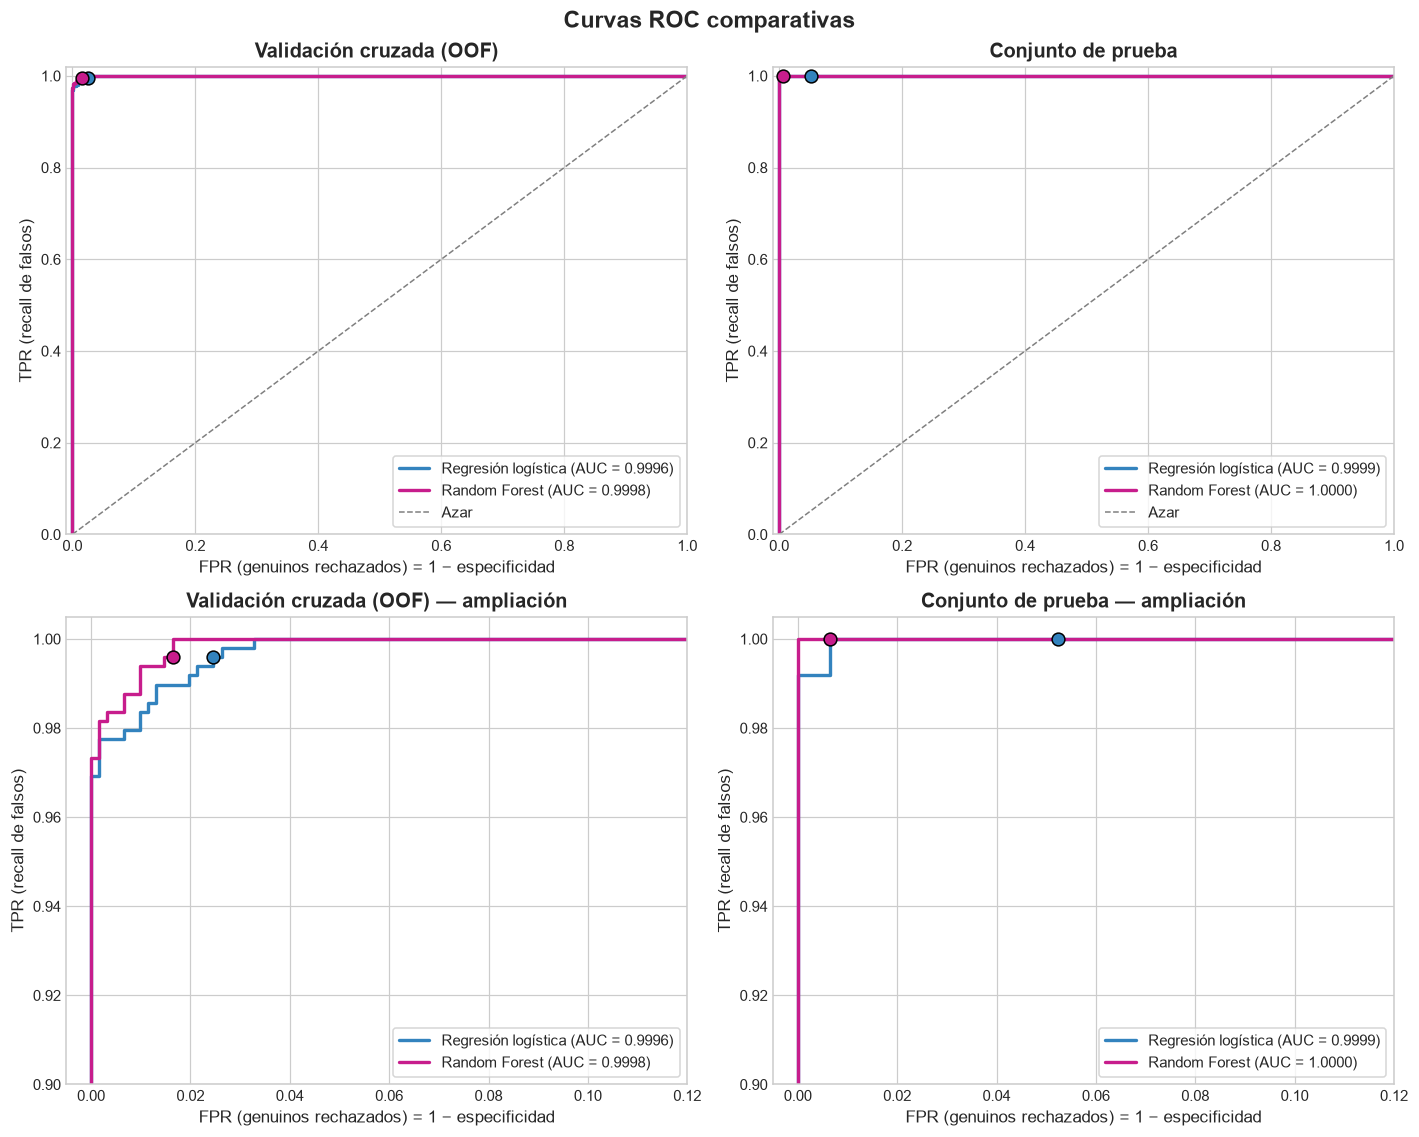

,AUC validación cruzada (OOF),AUC prueba
Regresión logística,0.99960,0.99995
Random Forest,0.99979,1.00000


In [10]:
def roc_panel(ax, y_true, probas, ops, zoom, title):
    for model, proba in probas.items():
        fpr, tpr, _ = roc_curve(y_true, proba)
        auc = roc_auc_score(y_true, proba)
        ax.plot(fpr, tpr, color=MODEL_COLORS[model], linewidth=2.2, label=f'{model} (AUC = {auc:.4f})')
        ax.scatter(*ops[model], s=70, color=MODEL_COLORS[model], edgecolor='black', zorder=5)
    if not zoom:
        ax.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=1, label='Azar')
        ax.set_xlim(-0.01, 1.0); ax.set_ylim(0, 1.02)
    else:
        ax.set_xlim(-0.005, 0.12); ax.set_ylim(0.9, 1.005)
        title += ' — ampliación'
    ax.set_xlabel('FPR (genuinos rechazados) = 1 − especificidad')
    ax.set_ylabel('TPR (recall de falsos)')
    ax.set_title(title)
    ax.legend(loc='lower right', frameon=True)


def operating_point(m):  # (FPR, TPR) con tau = 0.5
    return m['FP'] / (m['FP'] + m['TN']), m['recall_fake']


ops_cv = {MODEL_LR: operating_point(cv_metrics.loc[MODEL_LR]), MODEL_RF: operating_point(cv_metrics.loc[MODEL_RF])}
ops_test = {MODEL_LR: operating_point(test_metrics.loc[MODEL_LR]), MODEL_RF: operating_point(test_metrics.loc[MODEL_RF])}
probas_cv = {MODEL_LR: oof['proba_lr'], MODEL_RF: oof['proba_rf']}
probas_test = {MODEL_LR: proba_test_lr, MODEL_RF: proba_test_rf}

fig, axes = plt.subplots(2, 2, figsize=(13, 10.5))
roc_panel(axes[0, 0], oof['y_true'], probas_cv, ops_cv, False, 'Validación cruzada (OOF)')
roc_panel(axes[0, 1], y_test, probas_test, ops_test, False, 'Conjunto de prueba')
roc_panel(axes[1, 0], oof['y_true'], probas_cv, ops_cv, True, 'Validación cruzada (OOF)')
roc_panel(axes[1, 1], y_test, probas_test, ops_test, True, 'Conjunto de prueba')
fig.suptitle('Curvas ROC comparativas', fontsize=15, fontweight='bold')
plt.tight_layout()
fig.savefig(PLOTS_DIR / '12_curvas_roc_comparativas.png', dpi=300, bbox_inches='tight')
plt.show()

display(pd.DataFrame({
    'AUC validación cruzada (OOF)': cv_metrics['roc_auc'],
    'AUC prueba': test_metrics['roc_auc'],
}).round(5))

# 3.9 Prueba de hipótesis emparejada sobre la métrica principal

**Medida de rendimiento:** recall de la clase falsa en cada uno de los 5 pliegues. Como A y B usaron los mismos pliegues, se forman 5 pares y se trabaja con la diferencia $d_i = \text{recall}_{LR,i} - \text{recall}_{RF,i}$.

- $H_0$: $\mu_d = 0$ — el recall esperado de ambos modelos es el mismo.
- $H_1$: $\mu_d \neq 0$ — el recall esperado difiere (prueba bilateral).
- Nivel de significancia: $\alpha = 0.05$.
- **Prueba principal:** $t$ pareada con la corrección de Nadeau y Bengio (2003), $t = \dfrac{\bar d}{\sqrt{\left(\frac{1}{k} + \frac{n_{prueba}}{n_{entrenamiento}}\right) s_d^2}}$, con $k = 5$ pliegues y $k-1 = 4$ grados de libertad.
- **Referencia:** $t$ pareada convencional, $t = \dfrac{\bar d}{s_d/\sqrt{k}}$, que se muestra sin corregir y solo para comparar.

### Supuestos y precauciones

1. **Pareo:** cada par proviene de los mismos billetes de validación (verificado en 3.4).
2. **Normalidad de las diferencias:** con solo 5 pares la prueba de Shapiro–Wilk tiene muy poca potencia; se reporta como referencia.
3. **Independencia:** *no se cumple del todo*. Los conjuntos de entrenamiento de los pliegues se traslapan en ~75 %, lo que hace que la varianza de $\bar d$ se subestime y la prueba sea demasiado optimista. Por eso la prueba principal es la $t$ con **corrección de Nadeau y Bengio**, que reemplaza $1/k$ por $1/k + n_{prueba}/n_{entrenamiento}$ en la varianza. La $t$ convencional no corrige esta dependencia y se muestra solo como referencia. La corrección reduce el optimismo, pero no convierte 5 pliegues en una muestra independiente: la potencia para detectar diferencias pequeñas sigue siendo baja.
4. **Resolución:** cada pliegue tiene ~97–98 billetes falsos, así que un solo FN mueve el recall en ≈ 0.01.
5. **Caso degenerado:** si todas las diferencias fueran iguales ($s_d = 0$), el estadístico $t$ no está definido (división entre cero). El código lo trata de forma explícita: con diferencia media cero reporta $t = 0$ y $p = 1$; con diferencia media distinta de cero reporta $|t| = \infty$ y $p = 0$.

> **Cómo leer el resultado:** no rechazar $H_0$ **no** demuestra que los modelos sean equivalentes; solo indica que estos datos no bastan para detectar una diferencia. Para dimensionar qué diferencias son compatibles con los datos se reporta además un intervalo de confianza de 95 % para $\mu_d$.


In [11]:
alpha = 0.05
a = paired['recall_fake_lr'].to_numpy()
b = paired['recall_fake_rf'].to_numpy()
d = a - b
k = len(d)
dfree = k - 1
d_mean, d_sd = d.mean(), d.std(ddof=1)

# Corrección de Nadeau y Bengio: proporción prueba/entrenamiento de cada pliegue externo
ratio = np.mean([len(idx_val) / len(idx_tr) for idx_tr, idx_val in folds])
t_crit = stats.t.ppf(1 - alpha / 2, dfree)


def t_from_se(mean_diff, se, df_):
    # Devuelve (t, p). Si el error estándar es 0 el estadístico no está definido:
    # diferencia media 0 -> t = 0, p = 1; diferencia media distinta de 0 -> |t| = inf, p = 0.
    if se == 0:
        return (0.0, 1.0) if mean_diff == 0 else (float(np.sign(mean_diff) * np.inf), 0.0)
    t = mean_diff / se
    return t, 2 * stats.t.sf(abs(t), df_)


se_std = d_sd / np.sqrt(k)
se_nb = np.sqrt((1 / k + ratio) * d_sd ** 2)
t_std, p_std = t_from_se(d_mean, se_std, dfree)      # referencia (sin corregir)
t_nb, p_nb = t_from_se(d_mean, se_nb, dfree)         # prueba principal
if d_sd > 0:                                         # control cruzado con scipy
    check = stats.ttest_rel(a, b)
    assert np.isclose(t_std, check.statistic) and np.isclose(p_std, check.pvalue)

ci_std = (d_mean - t_crit * se_std, d_mean + t_crit * se_std)
ci_nb = (d_mean - t_crit * se_nb, d_mean + t_crit * se_nb)

sh_w, sh_p = stats.shapiro(d) if d_sd > 0 else (np.nan, np.nan)

tabla_d = pd.DataFrame({'recall_LR': a, 'recall_RF': b, 'd = LR − RF': d},
                       index=pd.RangeIndex(1, k + 1, name='fold'))
display(tabla_d.round(4))

print(f'Diferencia media (LR − RF): {d_mean:+.6f}   desviación estándar de d: {d_sd:.6f}')
print(f'Shapiro–Wilk de las diferencias: W = {sh_w:.4f}, p = {sh_p:.4f}  (n = {k}: potencia muy baja)')
print(f'PRUEBA PRINCIPAL — t con corrección N–B : t({dfree}) = {t_nb:+.4f}, p = {p_nb:.4f}, IC95 % de μ_d = [{ci_nb[0]:+.4f}, {ci_nb[1]:+.4f}]  (n_prueba/n_entrenamiento = {ratio:.3f})')
print(f'Referencia — t pareado convencional      : t({dfree}) = {t_std:+.4f}, p = {p_std:.4f}, IC95 % de μ_d = [{ci_std[0]:+.4f}, {ci_std[1]:+.4f}]  (no corrige la dependencia entre pliegues)')
decision_nb = 'NO se rechaza H0' if p_nb >= alpha else 'Se rechaza H0'
decision_std = 'NO se rechaza H0' if p_std >= alpha else 'Se rechaza H0'
print(f'Decisión con α = {alpha}: {decision_nb} (prueba principal, N–B) | {decision_std} (referencia, t convencional)')


,recall_LR,recall_RF,d = LR − RF
fold,,,
1,1.0000,1.0000,0.0000
2,0.9898,1.0000,-0.0102
3,1.0000,0.9898,0.0102
4,0.9897,1.0000,-0.0103
5,1.0000,0.9897,0.0103


Diferencia media (LR − RF): +0.000000   desviación estándar de d: 0.010257
Shapiro–Wilk de las diferencias: W = 0.8248, p = 0.1270  (n = 5: potencia muy baja)
PRUEBA PRINCIPAL — t con corrección N–B : t(4) = +0.0000, p = 1.0000, IC95 % de μ_d = [-0.0191, +0.0191]  (n_prueba/n_entrenamiento = 0.250)
Referencia — t pareado convencional      : t(4) = +0.0000, p = 1.0000, IC95 % de μ_d = [-0.0127, +0.0127]  (no corrige la dependencia entre pliegues)
Decisión con α = 0.05: NO se rechaza H0 (prueba principal, N–B) | NO se rechaza H0 (referencia, t convencional)


### Relevancia práctica frente a significancia estadística

Una diferencia puede ser estadísticamente significativa y casi irrelevante, o al revés. Por eso se traducen las diferencias a **billetes**: cuántas falsificaciones aceptadas (FN) y cuántos genuinos rechazados (FP) tiene cada modelo en las mismas 1,097 predicciones OOF.

,FN,FP,falsificaciones aceptadas (% de falsos),genuinos rechazados (% de genuinos)
Regresión logística,2,15,0.41,2.46
Random Forest,2,10,0.41,1.64


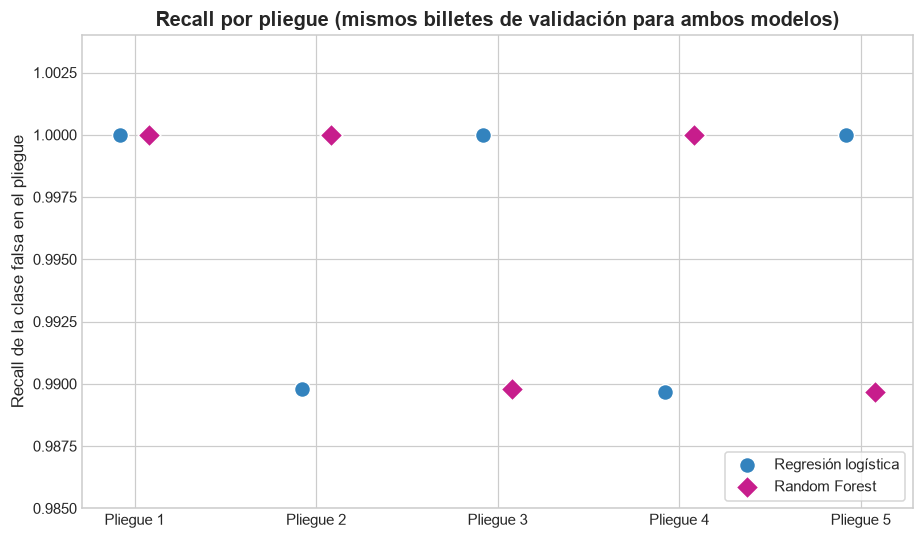

In [12]:
practical = cv_metrics[['FN', 'FP']].astype(int).copy()
practical['falsificaciones aceptadas (% de falsos)'] = (cv_metrics['FN'] / (cv_metrics['FN'] + cv_metrics['TP']) * 100).round(2)
practical['genuinos rechazados (% de genuinos)'] = (cv_metrics['FP'] / (cv_metrics['FP'] + cv_metrics['TN']) * 100).round(2)
display(practical)

fig, ax = plt.subplots(figsize=(8.5, 5))
folds_x = np.arange(1, k + 1)
ax.scatter(folds_x - 0.08, a, s=110, color=MODEL_COLORS[MODEL_LR], edgecolor='white', zorder=3, label=MODEL_LR)
ax.scatter(folds_x + 0.08, b, s=110, color=MODEL_COLORS[MODEL_RF], edgecolor='white', zorder=3, marker='D', label=MODEL_RF)
ax.set_xticks(folds_x, [f'Pliegue {i}' for i in folds_x])
ax.set_ylim(0.985, 1.004)
ax.set_ylabel('Recall de la clase falsa en el pliegue')
ax.set_title('Recall por pliegue (mismos billetes de validación para ambos modelos)')
ax.legend(loc='lower right', frameon=True)
plt.tight_layout()
fig.savefig(PLOTS_DIR / '13_recall_por_pliegue_pareado.png', dpi=300, bbox_inches='tight')
plt.show()

# 3.10 Billetes mal clasificados: falsos negativos y falsos positivos

Se identifica **cada billete** mal clasificado, en validación cruzada y en prueba, con su tipo de error, su probabilidad de ser falso y los valores de sus cuatro características. Después se comprueba si los dos modelos fallan en los **mismos** billetes.

Como el dataset tiene registros con características idénticas, se reportan dos conteos: las **filas** mal clasificadas y los **patrones de características distintos** que representan (las filas idénticas cuentan una sola vez).


In [13]:
def collect_errors(frame, y_true_col, pred_col, proba_col, model, subset, has_fold):
    wrong = frame[frame[y_true_col] != frame[pred_col]].copy()
    out = pd.DataFrame({
        'conjunto': subset, 'modelo': model,
        'fold': wrong['fold'].to_numpy() if has_fold else np.nan,
        'index': wrong['index'].to_numpy(),
        'y_true': wrong[y_true_col].to_numpy(), 'y_pred': wrong[pred_col].to_numpy(),
        'proba_fake': wrong[proba_col].to_numpy(),
    })
    out['tipo_error'] = np.where(out['y_true'] == 1, 'FN (falso aceptado)', 'FP (genuino rechazado)')
    return pd.concat([out.reset_index(drop=True),
                      df.loc[out['index'], FEATURES].reset_index(drop=True)], axis=1)


errors = pd.concat([
    collect_errors(oof, 'y_true', 'y_pred_lr', 'proba_lr', MODEL_LR, 'Validación cruzada (OOF)', True),
    collect_errors(oof, 'y_true', 'y_pred_rf', 'proba_rf', MODEL_RF, 'Validación cruzada (OOF)', True),
    collect_errors(test_predictions, 'y_true', 'y_pred_lr', 'proba_lr', MODEL_LR, 'Prueba', False),
    collect_errors(test_predictions, 'y_true', 'y_pred_rf', 'proba_rf', MODEL_RF, 'Prueba', False),
], ignore_index=True)

print('Número de billetes mal clasificados por conjunto, modelo y tipo de error:')
display(errors.groupby(['conjunto', 'modelo', 'tipo_error']).size().unstack(fill_value=0))

# Filas mal clasificadas frente a patrones de características distintos (filas idénticas cuentan una vez)
patron = errors[FEATURES].round(6).astype(str).apply('|'.join, axis=1)
print('Filas mal clasificadas y patrones de características distintos:')
display(errors.assign(patron=patron).groupby(['conjunto', 'modelo', 'tipo_error'])
        .agg(filas=('index', 'size'), patrones_distintos=('patron', 'nunique')))

print('Falsos negativos (falsificaciones aceptadas) — son el error costoso:')
display(errors[errors['tipo_error'].str.startswith('FN')]
        .sort_values(['conjunto', 'modelo', 'index']).round(4).reset_index(drop=True))

Número de billetes mal clasificados por conjunto, modelo y tipo de error:


tipo_error                                    FN (falso aceptado)  \
conjunto                 modelo                                     
Prueba                   Random Forest                          0   
                         Regresión logística                    0   
Validación cruzada (OOF) Random Forest                          2   
                         Regresión logística                    2   

tipo_error                                    FP (genuino rechazado)  
conjunto                 modelo                                       
Prueba                   Random Forest                             1  
                         Regresión logística                       8  
Validación cruzada (OOF) Random Forest                            10  
                         Regresión logística                      15

Filas mal clasificadas y patrones de características distintos:


filas  \
conjunto                 modelo              tipo_error                      
Prueba                   Random Forest       FP (genuino rechazado)      1   
                         Regresión logística FP (genuino rechazado)      8   
Validación cruzada (OOF) Random Forest       FN (falso aceptado)         2   
                                             FP (genuino rechazado)     10   
                         Regresión logística FN (falso aceptado)         2   
                                             FP (genuino rechazado)     15   

                                                                     patrones_distintos  
conjunto                 modelo              tipo_error                                  
Prueba                   Random Forest       FP (genuino rechazado)                   1  
                         Regresión logística FP (genuino rechazado)                   6  
Validación cruzada (OOF) Random Forest       FN (falso aceptado)                      2  
                                             FP (genuino rechazado)                  10  
                         Regresión logística FN (falso aceptado)                      2  
                                             FP (genuino rechazado)                   8

Falsos negativos (falsificaciones aceptadas) — son el error costoso:


,conjunto,modelo,fold,index,y_true,y_pred,proba_fake,tipo_error,variance,skewness,kurtosis,entropy
0,Validación cruzada (OOF),Random Forest,3.0,910,1,0,0.4389,FN (falso aceptado),0.5530,-3.4619,1.7048,1.1008
1,Validación cruzada (OOF),Random Forest,5.0,1075,1,0,0.4950,FN (falso aceptado),0.3764,-0.8236,0.7854,0.7452
2,Validación cruzada (OOF),Regresión logística,4.0,918,1,0,0.3672,FN (falso aceptado),2.3917,4.5565,-4.9888,-2.8987
3,Validación cruzada (OOF),Regresión logística,2.0,1101,1,0,0.4359,FN (falso aceptado),2.1943,4.5503,-4.9760,-2.7254


In [14]:
# ¿Fallan los dos modelos en los mismos billetes? (validación cruzada)
cv_err = errors[errors['conjunto'] == 'Validación cruzada (OOF)']
rows = []
for tipo in ['FN (falso aceptado)', 'FP (genuino rechazado)']:
    s_lr = set(cv_err[(cv_err['modelo'] == MODEL_LR) & (cv_err['tipo_error'] == tipo)]['index'])
    s_rf = set(cv_err[(cv_err['modelo'] == MODEL_RF) & (cv_err['tipo_error'] == tipo)]['index'])
    rows.append({'tipo de error': tipo, 'solo regresión logística': len(s_lr - s_rf),
                 'solo Random Forest': len(s_rf - s_lr), 'ambos modelos': len(s_lr & s_rf)})
overlap = pd.DataFrame(rows).set_index('tipo de error')
print('Billetes mal clasificados en validación cruzada (OOF), según qué modelo falla:')
display(overlap)

print('Billetes de prueba mal clasificados:')
test_err = errors[errors['conjunto'] == 'Prueba'].sort_values(['modelo', 'index']).round(4)
display(test_err.reset_index(drop=True) if len(test_err) else 'Ninguno')

Billetes mal clasificados en validación cruzada (OOF), según qué modelo falla:


,solo regresión logística,solo Random Forest,ambos modelos
tipo de error,,,
FN (falso aceptado),2,2,0
FP (genuino rechazado),15,10,0


Billetes de prueba mal clasificados:


,conjunto,modelo,fold,index,y_true,y_pred,proba_fake,tipo_error,variance,skewness,kurtosis,entropy
0,Prueba,Random Forest,NaN,95,0,1,0.7133,FP (genuino rechazado),-0.6447,-4.6062,8.3470,-2.7099
1,Prueba,Regresión logística,NaN,4,0,1,0.6911,FP (genuino rechazado),0.3292,-4.4552,4.5718,-0.9888
2,Prueba,Regresión logística,NaN,21,0,1,0.6911,FP (genuino rechazado),0.3292,-4.4552,4.5718,-0.9888
3,Prueba,Regresión logística,NaN,170,0,1,0.5541,FP (genuino rechazado),0.5706,-0.0248,1.2421,-0.5621
4,Prueba,Regresión logística,NaN,315,0,1,0.6911,FP (genuino rechazado),0.3292,-4.4552,4.5718,-0.9888
5,Prueba,Regresión logística,NaN,345,0,1,0.6338,FP (genuino rechazado),-1.8584,7.8860,-1.6643,-1.8384
6,Prueba,Regresión logística,NaN,476,0,1,0.6075,FP (genuino rechazado),0.3798,0.7098,0.7572,-0.4444
7,Prueba,Regresión logística,NaN,498,0,1,0.5541,FP (genuino rechazado),0.5706,-0.0248,1.2421,-0.5621
8,Prueba,Regresión logística,NaN,716,0,1,0.7349,FP (genuino rechazado),0.5195,-3.2633,3.0895,-0.9849


# 3.11 Efecto de los registros duplicados

El dataset tiene **24 filas duplicadas** (idénticas en las cuatro características y en la clase). Las parejas A y B decidieron conservarlas; el equipo acordó **medir su efecto y reportarlo**, sin eliminar nada.

El riesgo es que una fila quede en la validación de un pliegue y **un registro idéntico esté en el entrenamiento de ese mismo pliegue**: el modelo ya habría visto un registro con exactamente las mismas características y la estimación podría ser optimista. Dos filas con las mismas cuatro características y la misma clase no demuestran que sean el mismo billete físico; solo que son indistinguibles para el modelo. Aquí se cuenta cuántas filas están en esa situación y se recalculan las métricas OOF **sin ellas**; lo mismo se hace con las filas de `X_test` que tienen copia exacta en `X_train` (solo como análisis de sensibilidad; las tablas principales no cambian).

In [15]:
dup_mask_all = df.duplicated(keep=False)
dup_id = df.groupby(FEATURES + [TARGET]).ngroup()           # mismo id = filas idénticas

print(f'Filas duplicadas (según df.duplicated): {df.duplicated().sum()} | '
      f'filas que pertenecen a algún grupo repetido: {dup_mask_all.sum()} en {dup_id[dup_mask_all].nunique()} grupos')
print('Clase de las filas en grupos repetidos:', df.loc[dup_mask_all, TARGET].map(CLASS_LABELS).value_counts().to_dict())

# Filas de validación cuya copia exacta está en el entrenamiento de su pliegue
leaky_rows = []
for fold, (idx_tr, idx_val) in enumerate(folds, start=1):
    train_ids = set(dup_id.loc[X_train.index[idx_tr]])
    for lab in X_train.index[idx_val]:
        if dup_id.loc[lab] in train_ids:
            leaky_rows.append((fold, lab))
leaky = pd.DataFrame(leaky_rows, columns=['fold', 'index'])
oof['copia_en_entrenamiento'] = oof.set_index(['fold', 'index']).index.isin(leaky.set_index(['fold', 'index']).index)

test_dup_in_train = int(dup_id.loc[X_test.index].isin(set(dup_id.loc[X_train.index])).sum())
test_predictions['copia_en_entrenamiento'] = dup_id.loc[X_test.index].isin(set(dup_id.loc[X_train.index])).to_numpy()
print(f'Filas de validación con copia exacta en el entrenamiento de su pliegue: {len(leaky)} de {len(oof)}')
print(f'Filas de X_test con copia exacta en X_train: {test_dup_in_train} de {len(X_test)}')


def pooled(sub, suffix):
    yt, yp = sub['y_true'], sub[f'y_pred_{suffix}']
    tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
    return {'n': len(sub), 'recall_fake': tp / (tp + fn), 'precision_fake': tp / (tp + fp),
            'f1_fake': f1_score(yt, yp), 'accuracy': accuracy_score(yt, yp),
            'specificity': tn / (tn + fp), 'FN': fn, 'FP': fp}


sens_rows = {}
for label, sub in [('Todas las filas', oof), ('Sin filas con copia en el entrenamiento', oof[~oof['copia_en_entrenamiento']])]:
    for model, suffix in [(MODEL_LR, 'lr'), (MODEL_RF, 'rf')]:
        sens_rows[(label, model)] = pooled(sub, suffix)
sensitivity = pd.DataFrame(sens_rows).T
sensitivity.index.names = ['conjunto de filas', 'modelo']
display(sensitivity.round(4))

wrong_with_copy = oof[oof['copia_en_entrenamiento'] & ((oof['y_true'] != oof['y_pred_lr']) | (oof['y_true'] != oof['y_pred_rf']))]
print(f'Billetes mal clasificados (por al menos un modelo) que tenían copia en el entrenamiento: {len(wrong_with_copy)}')

# Efecto en el conjunto de prueba: métricas sin las filas de X_test que tienen copia exacta en X_train
test_sens = {}
for label, mask in [('Todas las filas de X_test', np.ones(len(test_predictions), dtype=bool)),
                    ('Sin filas con copia en X_train', ~test_predictions['copia_en_entrenamiento'].to_numpy())]:
    sub = test_predictions[mask]
    for model, suffix in [(MODEL_LR, 'lr'), (MODEL_RF, 'rf')]:
        test_sens[(label, model)] = pooled(sub, suffix)
test_sensitivity = pd.DataFrame(test_sens).T
test_sensitivity.index.names = ['conjunto de filas', 'modelo']
print('Conjunto de prueba, con y sin las filas que tienen copia exacta en X_train:')
display(test_sensitivity.round(4))

# Marca, en la tabla de errores, qué billetes tenían copia exacta en el entrenamiento
leaky_keys = set(map(tuple, leaky[['fold', 'index']].to_numpy()))
test_flag = dict(zip(test_predictions['index'], test_predictions['copia_en_entrenamiento']))
errors['copia_en_entrenamiento'] = [
    test_flag[r['index']] if r['conjunto'] == 'Prueba' else (int(r['fold']), int(r['index'])) in leaky_keys
    for _, r in errors.iterrows()
]
print('Billetes mal clasificados que tenían copia exacta en el entrenamiento:')
display(errors.groupby(['conjunto', 'modelo', 'tipo_error'])['copia_en_entrenamiento']
        .agg(['sum', 'count']).rename(columns={'sum': 'con copia', 'count': 'total'}))

Filas duplicadas (según df.duplicated): 24 | filas que pertenecen a algún grupo repetido: 35 en 11 grupos
Clase de las filas en grupos repetidos: {'Genuino (0)': 35}
Filas de validación con copia exacta en el entrenamiento de su pliegue: 23 de 1097
Filas de X_test con copia exacta en X_train: 9 de 275


n  \
conjunto de filas                       modelo                        
Todas las filas                         Regresión logística  1097.0   
                                        Random Forest        1097.0   
Sin filas con copia en el entrenamiento Regresión logística  1074.0   
                                        Random Forest        1074.0   

                                                             recall_fake  \
conjunto de filas                       modelo                             
Todas las filas                         Regresión logística       0.9959   
                                        Random Forest             0.9959   
Sin filas con copia en el entrenamiento Regresión logística       0.9959   
                                        Random Forest             0.9959   

                                                             precision_fake  \
conjunto de filas                       modelo                                
Todas las filas                         Regresión logística          0.9701   
                                        Random Forest                0.9798   
Sin filas con copia en el entrenamiento Regresión logística          0.9898   
                                        Random Forest                0.9798   

                                                             f1_fake  \
conjunto de filas                       modelo                         
Todas las filas                         Regresión logística   0.9828   
                                        Random Forest         0.9878   
Sin filas con copia en el entrenamiento Regresión logística   0.9928   
                                        Random Forest         0.9878   

                                                             accuracy  \
conjunto de filas                       modelo                          
Todas las filas                         Regresión logística    0.9845   
                                        Random Forest          0.9891   
Sin filas con copia en el entrenamiento Regresión logística    0.9935   
                                        Random Forest          0.9888   

                                                             specificity   FN  \
conjunto de filas                       modelo                                  
Todas las filas                         Regresión logística       0.9754  2.0   
                                        Random Forest             0.9836  2.0   
Sin filas con copia en el entrenamiento Regresión logística       0.9915  2.0   
                                        Random Forest             0.9829  2.0   

                                                               FP  
conjunto de filas                       modelo                     
Todas las filas                         Regresión logística  15.0  
                                        Random Forest        10.0  
Sin filas con copia en el entrenamiento Regresión logística   5.0  
                                        Random Forest        10.0

Billetes mal clasificados (por al menos un modelo) que tenían copia en el entrenamiento: 10
Conjunto de prueba, con y sin las filas que tienen copia exacta en X_train:


n  recall_fake  \
conjunto de filas              modelo                                    
Todas las filas de X_test      Regresión logística  275.0          1.0   
                               Random Forest        275.0          1.0   
Sin filas con copia en X_train Regresión logística  266.0          1.0   
                               Random Forest        266.0          1.0   

                                                    precision_fake  f1_fake  \
conjunto de filas              modelo                                         
Todas las filas de X_test      Regresión logística          0.9385   0.9683   
                               Random Forest                0.9919   0.9959   
Sin filas con copia en X_train Regresión logística          0.9919   0.9959   
                               Random Forest                0.9919   0.9959   

                                                    accuracy  specificity  \
conjunto de filas              modelo                                       
Todas las filas de X_test      Regresión logística    0.9709       0.9477   
                               Random Forest          0.9964       0.9935   
Sin filas con copia en X_train Regresión logística    0.9962       0.9931   
                               Random Forest          0.9962       0.9931   

                                                     FN   FP  
conjunto de filas              modelo                         
Todas las filas de X_test      Regresión logística  0.0  8.0  
                               Random Forest        0.0  1.0  
Sin filas con copia en X_train Regresión logística  0.0  1.0  
                               Random Forest        0.0  1.0

Billetes mal clasificados que tenían copia exacta en el entrenamiento:


con copia  \
conjunto                 modelo              tipo_error                          
Prueba                   Random Forest       FP (genuino rechazado)          0   
                         Regresión logística FP (genuino rechazado)          7   
Validación cruzada (OOF) Random Forest       FN (falso aceptado)             0   
                                             FP (genuino rechazado)          0   
                         Regresión logística FN (falso aceptado)             0   
                                             FP (genuino rechazado)         10   

                                                                     total  
conjunto                 modelo              tipo_error                     
Prueba                   Random Forest       FP (genuino rechazado)      1  
                         Regresión logística FP (genuino rechazado)      8  
Validación cruzada (OOF) Random Forest       FN (falso aceptado)         2  
                                             FP (genuino rechazado)     10  
                         Regresión logística FN (falso aceptado)         2  
                                             FP (genuino rechazado)     15

# 3.12 Exportación de resultados de la pareja C

Se guardan en `../results/pareja_c/` (misma convención de nombres que B) los archivos que respaldan las tablas y figuras del artículo. Las figuras ya quedaron en `../report/plots/` (`11_` a `13_`).

| Archivo | Contenido |
|---|---|
| `01_c_mediciones_por_pliegue.csv` | Métricas por pliegue de **ambos** modelos, con especificidad, AUC y conteos TN/FP/FN/TP (incluye las columnas que consume la prueba estadística) |
| `02_c_predicciones_fuera_de_muestra.csv` | Predicción y probabilidad OOF de cada billete de `X_train`, para ambos modelos |
| `03_c_metricas_cv_y_prueba.csv` | Métricas principal y complementarias, con conteos TN/FP/FN/TP, en validación cruzada y en prueba |
| `04_c_prueba_estadistica.txt` | Hipótesis, α, supuestos, estadísticos, p-valores e intervalos |
| `05_c_predicciones_prueba.csv` | Predicción y probabilidad de cada billete de `X_test` |
| `06_c_billetes_mal_clasificados.csv` | Cada billete mal clasificado, con tipo de error y características |
| `07_c_sensibilidad_duplicados.csv` | Métricas OOF y de prueba con y sin las filas que tienen copia exacta en el entrenamiento |
| `08_c_versiones_software.txt` | Versiones de software y semilla |
| `09_c_resumen_por_pliegue.csv` | Tabla principal: media ± desviación estándar por pliegue de cada métrica, para ambos modelos |

In [16]:
folds_full.to_csv(RESULTS_DIR / '01_c_mediciones_por_pliegue.csv')
summary_cv.to_csv(RESULTS_DIR / '09_c_resumen_por_pliegue.csv')
oof.to_csv(RESULTS_DIR / '02_c_predicciones_fuera_de_muestra.csv', index=False)

metrics_export = pd.concat({'Validación cruzada (OOF)': cv_metrics, 'Prueba': test_metrics}, names=['conjunto', 'modelo'])
metrics_export.to_csv(RESULTS_DIR / '03_c_metricas_cv_y_prueba.csv')

report = f'''PRUEBA DE HIPÓTESIS EMPAREJADA — recall de la clase falsa (clase 1), 5 pliegues
{'=' * 78}
Medida: recall de falsos por pliegue; diferencia d_i = recall_LR,i - recall_RF,i (pliegues idénticos para ambos modelos)
H0: mu_d = 0 (el recall esperado de ambos modelos es el mismo)
H1: mu_d != 0 (prueba bilateral)
alpha = {alpha}

Recall por pliegue  LR: {np.round(a, 4).tolist()}
Recall por pliegue  RF: {np.round(b, 4).tolist()}
Diferencias d_i       : {np.round(d, 4).tolist()}
Diferencia media      : {d_mean:+.6f}   (desv. est. de d = {d_sd:.6f}, k = {k})

Supuestos: pareo (verificado); normalidad de d -> Shapiro-Wilk W = {sh_w:.4f}, p = {sh_p:.4f} (n = 5, potencia muy baja);
independencia entre pliegues: no se cumple del todo (entrenamientos traslapados) -> la prueba principal es la t con corrección de Nadeau y Bengio; la t convencional se reporta solo como referencia.

PRUEBA PRINCIPAL - t corregido (N-B): t({dfree}) = {t_nb:+.4f}, p = {p_nb:.4f}, IC95% de mu_d = [{ci_nb[0]:+.4f}, {ci_nb[1]:+.4f}]  (n_prueba/n_entrenamiento = {ratio:.3f})
Referencia - t pareado convencional (no corrige la dependencia entre pliegues): t({dfree}) = {t_std:+.4f}, p = {p_std:.4f}, IC95% de mu_d = [{ci_std[0]:+.4f}, {ci_std[1]:+.4f}]
Decisión (alpha = {alpha}): {decision_nb} (prueba principal); {decision_std} (referencia)

Interpretación: no rechazar H0 no demuestra equivalencia; solo indica que estos datos no permiten detectar una diferencia en el recall.
Billetes (validación cruzada, 1,097 predicciones): LR FN = {int(cv_metrics.loc[MODEL_LR, 'FN'])}, FP = {int(cv_metrics.loc[MODEL_LR, 'FP'])}; RF FN = {int(cv_metrics.loc[MODEL_RF, 'FN'])}, FP = {int(cv_metrics.loc[MODEL_RF, 'FP'])}.
'''
(RESULTS_DIR / '04_c_prueba_estadistica.txt').write_text(report, encoding='utf-8')

test_predictions.to_csv(RESULTS_DIR / '05_c_predicciones_prueba.csv', index=False)
errors.to_csv(RESULTS_DIR / '06_c_billetes_mal_clasificados.csv', index=False)
pd.concat({'Validación cruzada (OOF)': sensitivity, 'Prueba': test_sensitivity}, names=['conjunto']).to_csv(
    RESULTS_DIR / '07_c_sensibilidad_duplicados.csv')
(RESULTS_DIR / '08_c_versiones_software.txt').write_text(
    '\n'.join(f'{k}: {v}' for k, v in versions.items()) + f'\nrandom_state: {RANDOM_STATE}\n', encoding='utf-8')

print('Archivos guardados en', RESULTS_DIR.resolve())
for p in sorted(RESULTS_DIR.iterdir()):
    print(' -', p.name)

Archivos guardados en C:\Users\Garcia\Desktop\Diana\UNIVERSIDAD\5to Semestre\Aprendizaje de Máquina\results\pareja_c
 - 01_c_mediciones_por_pliegue.csv
 - 02_c_predicciones_fuera_de_muestra.csv
 - 03_c_metricas_cv_y_prueba.csv
 - 04_c_prueba_estadistica.txt
 - 05_c_predicciones_prueba.csv
 - 06_c_billetes_mal_clasificados.csv
 - 07_c_sensibilidad_duplicados.csv
 - 08_c_versiones_software.txt
 - 09_c_resumen_por_pliegue.csv


# 3.13 Resumen de resultados de la pareja C

Resumen generado automáticamente a partir de las tablas anteriores (no contiene cifras escritas a mano).

In [17]:
def line(model, m):
    return (f"  {model:<20} recall={m['recall_fake']:.4f}  precision={m['precision_fake']:.4f}  F1={m['f1_fake']:.4f}  "
            f"especificidad={m['specificity']:.4f}  AUC={m['roc_auc']:.5f}  FN={int(m['FN'])}  FP={int(m['FP'])}")

print('Validación cruzada, media ± desviación estándar por pliegue (tabla principal):')
for m in FULL_METRICS:
    print(f"  {m:<15} {MODEL_LR}: {summary_cv.loc[m, MODEL_LR]}   |   {MODEL_RF}: {summary_cv.loc[m, MODEL_RF]}")
print('\nValidación cruzada (OOF agrupado, 1,097 billetes; para matrices, ROC y errores):')
for model in (MODEL_LR, MODEL_RF):
    print(line(model, cv_metrics.loc[model]))
print(f'\nConjunto de prueba ({len(X_test)} billetes, evaluado una sola vez):')
for model in (MODEL_LR, MODEL_RF):
    print(line(model, test_metrics.loc[model]))
print(f'\nPrueba sobre el recall por pliegue (LR − RF): diferencia media = {d_mean:+.6f}')
print(f'  Prueba principal (t con corrección N–B): t({dfree}) = {t_nb:+.4f}, p = {p_nb:.4f}')
print(f'  IC95 % (corregido) de la diferencia: [{ci_nb[0]:+.4f}, {ci_nb[1]:+.4f}]')
print(f'  Referencia (t pareado convencional)  : t({dfree}) = {t_std:+.4f}, p = {p_std:.4f}')
print(f'\nDuplicados: {len(leaky)} filas de validación tenían copia exacta en el entrenamiento de su pliegue.')
for model in (MODEL_LR, MODEL_RF):
    m = sensitivity.loc[('Sin filas con copia en el entrenamiento', model)]
    print(f"  OOF sin esas filas — {model:<20} FN={int(m['FN'])}  FP={int(m['FP'])}  precision={m['precision_fake']:.4f}")
for model in (MODEL_LR, MODEL_RF):
    m = test_sensitivity.loc[('Sin filas con copia en X_train', model)]
    print(f"  Prueba sin filas con copia en X_train — {model:<20} FN={int(m['FN'])}  FP={int(m['FP'])}  n={int(m['n'])}")

Validación cruzada, media ± desviación estándar por pliegue (tabla principal):
  recall_fake     Regresión logística: 0.9959 ± 0.0056   |   Random Forest: 0.9959 ± 0.0056
  precision_fake  Regresión logística: 0.9703 ± 0.0153   |   Random Forest: 0.9801 ± 0.0209
  f1_fake         Regresión logística: 0.9829 ± 0.0084   |   Random Forest: 0.9879 ± 0.0131
  accuracy        Regresión logística: 0.9845 ± 0.0076   |   Random Forest: 0.9890 ± 0.0119
  specificity     Regresión logística: 0.9754 ± 0.0130   |   Random Forest: 0.9835 ± 0.0175
  roc_auc         Regresión logística: 0.9997 ± 0.0002   |   Random Forest: 0.9998 ± 0.0002

Validación cruzada (OOF agrupado, 1,097 billetes; para matrices, ROC y errores):
  Regresión logística  recall=0.9959  precision=0.9701  F1=0.9828  especificidad=0.9754  AUC=0.99960  FN=2  FP=15
  Random Forest        recall=0.9959  precision=0.9798  F1=0.9878  especificidad=0.9836  AUC=0.99979  FN=2  FP=10

Conjunto de prueba (275 billetes, evaluado una sola vez):


# 3.14 Conclusiones de la pareja C

El texto se genera a partir de las tablas de 3.5 a 3.11, de modo que las cifras no están escritas a mano: si cambia algún cálculo, el texto se actualiza. Antes de redactar, la celda comprueba los supuestos en los que se apoya la redacción (por ejemplo, que el Random Forest no falle en filas con copia) y se detiene si alguno deja de cumplirse. Las métricas por pliegue se reportan como media ± desviación estándar de los cinco pliegues; las predicciones agrupadas (1,097 predicciones fuera de muestra) se usan para los conteos de errores.

In [18]:
from IPython.display import Markdown, display

# ---------- Cifras tomadas de las tablas de 3.5 a 3.11 ----------
LR, RF = MODEL_LR, MODEL_RF
CV, TE = 'Validación cruzada (OOF)', 'Prueba'
FN_T, FP_T = 'FN (falso aceptado)', 'FP (genuino rechazado)'


def ms(frame, col):
    return f'{frame[col].mean():.4f} ± {frame[col].std(ddof=1):.4f}'


n_fake_cv = int(cv_metrics.loc[LR, 'FN'] + cv_metrics.loc[LR, 'TP'])
n_fake_te = int(test_metrics.loc[LR, 'FN'] + test_metrics.loc[LR, 'TP'])
fn_cv = {m: int(cv_metrics.loc[m, 'FN']) for m in (LR, RF)}
fp_cv = {m: int(cv_metrics.loc[m, 'FP']) for m in (LR, RF)}
fn_te = {m: int(test_metrics.loc[m, 'FN']) for m in (LR, RF)}
fp_te = {m: int(test_metrics.loc[m, 'FP']) for m in (LR, RF)}

fn_cv_rows = errors[(errors['conjunto'] == CV) & (errors['tipo_error'] == FN_T)]
p_min, p_max = fn_cv_rows['proba_fake'].min(), fn_cv_rows['proba_fake'].max()

# Duplicados
n_dup_rows = int(dup_mask_all.sum())
n_dup_groups = int(dup_id[dup_mask_all].nunique())
dup_only_genuine = set(df.loc[dup_mask_all, TARGET]) == {0}
copy_flag = errors['copia_en_entrenamiento'].astype(bool)


def fp_with_copy(subset, model):
    sel = (errors['conjunto'] == subset) & (errors['modelo'] == model) & (errors['tipo_error'] == FP_T)
    return int(copy_flag[sel].sum())


copy_cv = {m: fp_with_copy(CV, m) for m in (LR, RF)}
copy_te = {m: fp_with_copy(TE, m) for m in (LR, RF)}
ALL_CV, NOCOPY_CV = 'Todas las filas', 'Sin filas con copia en el entrenamiento'
ALL_TE, NOCOPY_TE = 'Todas las filas de X_test', 'Sin filas con copia en X_train'
fp_cv_sin = {m: int(sensitivity.loc[(NOCOPY_CV, m), 'FP']) for m in (LR, RF)}
fp_te_sin = {m: int(test_sensitivity.loc[(NOCOPY_TE, m), 'FP']) for m in (LR, RF)}

pat = errors[FEATURES].round(6).astype(str).apply('|'.join, axis=1)
lr_fp = errors[(errors['modelo'] == LR) & (errors['tipo_error'] == FP_T)]
pat_cv = pat[lr_fp[lr_fp['conjunto'] == CV].index].nunique()
pat_te = pat[lr_fp[lr_fp['conjunto'] == TE].index].nunique()

# ---------- Comprobaciones: la redacción solo es válida si se cumple esto ----------
# Si alguna falla, el cálculo cambió y hay que revisar el texto antes de entregarlo.
supuestos = {
    'mismo recall por pliegue en ambos modelos': ms(fold_lr_full, 'recall_fake') == ms(fold_rf_full, 'recall_fake'),
    'mismo número de FN en validación': fn_cv[LR] == fn_cv[RF],
    'ningún FN en prueba': fn_te[LR] == fn_te[RF] == 0,
    'ningún billete es FN en ambos modelos': int(overlap.loc[FN_T, 'ambos modelos']) == 0,
    'no se rechaza H0 con N-B ni con la t convencional': p_nb >= alpha and p_std >= alpha,
    'RF con menos FP que LR en el análisis original': fp_cv[RF] < fp_cv[LR] and fp_te[RF] < fp_te[LR],
    'duplicados solo de la clase genuina': dup_only_genuine,
    'RF no falla en filas con copia': copy_cv[RF] == 0 and copy_te[RF] == 0,
    'FP del RF iguales con y sin filas con copia': fp_cv_sin[RF] == fp_cv[RF] and fp_te_sin[RF] == fp_te[RF],
    'LR baja sus FP al quitar filas con copia': fp_cv_sin[LR] < fp_cv[LR] and fp_te_sin[LR] < fp_te[LR],
    'sin copias, LR no tiene más FP que RF': fp_cv_sin[LR] <= fp_cv_sin[RF] and fp_te_sin[LR] <= fp_te_sin[RF],
    'RF con min_samples_leaf=1 en todos los pliegues y en el modelo final':
        set(rf_folds['best_min_samples_leaf']) == {1} and rf_params['min_samples_leaf'] == 1,
    'precisión y F1 por pliegue: diferencia menor que la desviación estándar':
        abs(fold_rf_full['precision_fake'].mean() - fold_lr_full['precision_fake'].mean())
        < max(fold_lr_full['precision_fake'].std(ddof=1), fold_rf_full['precision_fake'].std(ddof=1))
        and abs(fold_rf_full['f1_fake'].mean() - fold_lr_full['f1_fake'].mean())
        < max(fold_lr_full['f1_fake'].std(ddof=1), fold_rf_full['f1_fake'].std(ddof=1)),
}
fallidos = [k for k, ok in supuestos.items() if not ok]
assert not fallidos, f'La redacción de 3.14 ya no coincide con los resultados. Revisar: {fallidos}'

# ---------- Texto ----------
ci_max = max(abs(ci_nb[0]), abs(ci_nb[1])) * 100
texto = f"""
## Detección de falsificaciones (métrica principal)

Ambos modelos alcanzaron un recall muy cercano a uno: {ms(fold_lr_full, 'recall_fake')} en validación cruzada (media ± desviación estándar de los cinco pliegues). En las predicciones agrupadas cada uno aceptó {fn_cv[LR]} falsificaciones de {n_fake_cv} (FN = {fn_cv[LR]}), y en el conjunto de prueba ninguno aceptó alguna (FN = 0 de {n_fake_te}). Los {len(fn_cv_rows)} FN de validación corresponden a billetes distintos, con probabilidades estimadas de ser falso entre {p_min:.3f} y {p_max:.3f}, es decir, cercanas al umbral de decisión. Tener la misma cantidad de errores no implica cometer los mismos errores. El AUC por pliegue fue {ms(fold_lr_full, 'roc_auc')} (regresión logística) y {ms(fold_rf_full, 'roc_auc')} (Random Forest): ambos separan casi perfectamente las dos clases.

## Comparación estadística

La diferencia media de recall entre los modelos fue {d_mean:+.4f}. Con la prueba principal (t pareada con corrección de Nadeau y Bengio) se obtuvo t({dfree}) = {t_nb:.4f} y p = {p_nb:.4f}, con un IC95 % de la diferencia de [{ci_nb[0]:+.4f}, {ci_nb[1]:+.4f}]. La t pareada convencional, mostrada como referencia, lleva a la misma decisión. No se rechaza $H_0$: no hay evidencia de que un modelo detecte más falsificaciones que el otro. Esto no demuestra que sean equivalentes: con cinco pares, el intervalo todavía admite diferencias de hasta {ci_max:.1f} puntos porcentuales en cualquier sentido, y la corrección de Nadeau y Bengio reduce el optimismo de la prueba pero no convierte cinco pliegues en una muestra independiente.

## Billetes genuinos rechazados y registros repetidos

Con todas las filas, el Random Forest rechazó menos billetes genuinos: {fp_cv[RF]} frente a {fp_cv[LR]} FP en validación y {fp_te[RF]} frente a {fp_te[LR]} en prueba (especificidad por pliegue de {ms(fold_rf_full, 'specificity')} frente a {ms(fold_lr_full, 'specificity')}). Esa diferencia hay que leerla junto con los registros repetidos. El dataset tiene {n_dup_rows} filas repartidas en {n_dup_groups} grupos de registros idénticos, todas de la clase genuina. De las {len(oof):,} filas de validación, {len(leaky)} tenían un registro idéntico en el entrenamiento de su pliegue; de las {len(X_test)} filas de prueba, {test_dup_in_train} lo tenían en `X_train`.

La regresión logística cometió {copy_cv[LR]} de sus {fp_cv[LR]} FP de validación y {copy_te[LR]} de sus {fp_te[LR]} FP de prueba sobre filas con copia en el entrenamiento. El Random Forest no cometió ninguno de los suyos sobre ese tipo de filas, de modo que sus FP no dependen de los duplicados: tiene {fp_cv_sin[RF]} FP en validación con y sin esas filas, y {fp_te_sin[RF]} en prueba con y sin ellas. Lo que cambia es la regresión logística, que al excluirlas baja de {fp_cv[LR]} a {fp_cv_sin[LR]} FP en validación y de {fp_te[LR]} a {fp_te_sin[LR]} en prueba.

En resumen, la desventaja aparente de la regresión logística en FP se concentra en filas con registro idéntico en el entrenamiento; sin ellas, la diferencia desaparece (prueba) o se invierte (validación cruzada). Esta comparación es descriptiva y no se contrastó estadísticamente.

Una hipótesis, que este análisis no prueba, es que el Random Forest, al no estar podado (`min_samples_leaf=1` en todos los pliegues y en el modelo final), clasifica bien esas filas porque ya vio un registro idéntico en el entrenamiento, mientras que la regresión logística, con una frontera lineal, vuelve a equivocarse en ellas. Comprobarla exigiría una validación cruzada agrupada por registro idéntico. Además, esos registros son indistinguibles para el modelo, pero no se afirma que correspondan al mismo billete físico, y las filas mal clasificadas no son errores independientes: los {fp_te[LR]} FP de la regresión logística en prueba corresponden a {pat_te} patrones de características distintos, y los {fp_cv[LR]} de validación a {pat_cv}.

## Respuesta a la pregunta de investigación

En la métrica principal, el recall de la clase falsa, no hay diferencia distinguible entre los modelos: ambos detectan casi todas las falsificaciones y la diferencia no es estadísticamente distinguible de cero. En precisión y F1 por pliegue el Random Forest sale algo mejor (precisión {ms(fold_rf_full, 'precision_fake')} frente a {ms(fold_lr_full, 'precision_fake')}; F1 {ms(fold_rf_full, 'f1_fake')} frente a {ms(fold_lr_full, 'f1_fake')}), pero esas diferencias quedan dentro de la desviación estándar entre pliegues. Las diferencias en FP no son concluyentes: dependen de cómo se reparten los registros repetidos entre entrenamiento y validación y no se contrastaron con una prueba estadística. Por tanto, con este experimento no se puede declarar que un modelo identifique mejor los billetes falsos que el otro; si hubiera que elegir, la decisión tendría que apoyarse en criterios que aquí no se evaluaron, como la interpretabilidad o el costo de cómputo.

## Limitaciones

- Una sola semilla y una sola partición 80/20; los resultados de prueba dependen de qué billetes quedaron en `X_test` ({len(X_test)} billetes, {n_fake_te} falsos).
- La comparación estadística usa solo cinco pares de diferencias y tiene baja potencia para detectar diferencias pequeñas.
- La validación cruzada no es agrupada: registros idénticos pudieron quedar en entrenamiento y validación. La validación por grupos de registros idénticos (`StratifiedGroupKFold`) es una mejora posible, pero exigiría volver a ejecutar ambos modelos con el mismo esquema.
- Los FN se ubicaron cerca del umbral 0.5. Un umbral guiado por costos podría reducirlos, pero debería seleccionarse con datos de entrenamiento o validación y nunca con `X_test`; no se implementó.
- La regresión logística se usó como línea base sin ajuste de hiperparámetros, mientras que el Random Forest recibió una búsqueda anidada.
"""
display(Markdown(texto))



## Detección de falsificaciones (métrica principal)

Ambos modelos alcanzaron un recall muy cercano a uno: 0.9959 ± 0.0056 en validación cruzada (media ± desviación estándar de los cinco pliegues). En las predicciones agrupadas cada uno aceptó 2 falsificaciones de 488 (FN = 2), y en el conjunto de prueba ninguno aceptó alguna (FN = 0 de 122). Los 4 FN de validación corresponden a billetes distintos, con probabilidades estimadas de ser falso entre 0.367 y 0.495, es decir, cercanas al umbral de decisión. Tener la misma cantidad de errores no implica cometer los mismos errores. El AUC por pliegue fue 0.9997 ± 0.0002 (regresión logística) y 0.9998 ± 0.0002 (Random Forest): ambos separan casi perfectamente las dos clases.

## Comparación estadística

La diferencia media de recall entre los modelos fue +0.0000. Con la prueba principal (t pareada con corrección de Nadeau y Bengio) se obtuvo t(4) = 0.0000 y p = 1.0000, con un IC95 % de la diferencia de [-0.0191, +0.0191]. La t pareada convencional, mostrada como referencia, lleva a la misma decisión. No se rechaza $H_0$: no hay evidencia de que un modelo detecte más falsificaciones que el otro. Esto no demuestra que sean equivalentes: con cinco pares, el intervalo todavía admite diferencias de hasta 1.9 puntos porcentuales en cualquier sentido, y la corrección de Nadeau y Bengio reduce el optimismo de la prueba pero no convierte cinco pliegues en una muestra independiente.

## Billetes genuinos rechazados y registros repetidos

Con todas las filas, el Random Forest rechazó menos billetes genuinos: 10 frente a 15 FP en validación y 1 frente a 8 en prueba (especificidad por pliegue de 0.9835 ± 0.0175 frente a 0.9754 ± 0.0130). Esa diferencia hay que leerla junto con los registros repetidos. El dataset tiene 35 filas repartidas en 11 grupos de registros idénticos, todas de la clase genuina. De las 1,097 filas de validación, 23 tenían un registro idéntico en el entrenamiento de su pliegue; de las 275 filas de prueba, 9 lo tenían en `X_train`.

La regresión logística cometió 10 de sus 15 FP de validación y 7 de sus 8 FP de prueba sobre filas con copia en el entrenamiento. El Random Forest no cometió ninguno de los suyos sobre ese tipo de filas, de modo que sus FP no dependen de los duplicados: tiene 10 FP en validación con y sin esas filas, y 1 en prueba con y sin ellas. Lo que cambia es la regresión logística, que al excluirlas baja de 15 a 5 FP en validación y de 8 a 1 en prueba.

En resumen, la desventaja aparente de la regresión logística en FP se concentra en filas con registro idéntico en el entrenamiento; sin ellas, la diferencia desaparece (prueba) o se invierte (validación cruzada). Esta comparación es descriptiva y no se contrastó estadísticamente.

Una hipótesis, que este análisis no prueba, es que el Random Forest, al no estar podado (`min_samples_leaf=1` en todos los pliegues y en el modelo final), clasifica bien esas filas porque ya vio un registro idéntico en el entrenamiento, mientras que la regresión logística, con una frontera lineal, vuelve a equivocarse en ellas. Comprobarla exigiría una validación cruzada agrupada por registro idéntico. Además, esos registros son indistinguibles para el modelo, pero no se afirma que correspondan al mismo billete físico, y las filas mal clasificadas no son errores independientes: los 8 FP de la regresión logística en prueba corresponden a 6 patrones de características distintos, y los 15 de validación a 8.

## Respuesta a la pregunta de investigación

En la métrica principal, el recall de la clase falsa, no hay diferencia distinguible entre los modelos: ambos detectan casi todas las falsificaciones y la diferencia no es estadísticamente distinguible de cero. En precisión y F1 por pliegue el Random Forest sale algo mejor (precisión 0.9801 ± 0.0209 frente a 0.9703 ± 0.0153; F1 0.9879 ± 0.0131 frente a 0.9829 ± 0.0084), pero esas diferencias quedan dentro de la desviación estándar entre pliegues. Las diferencias en FP no son concluyentes: dependen de cómo se reparten los registros repetidos entre entrenamiento y validación y no se contrastaron con una prueba estadística. Por tanto, con este experimento no se puede declarar que un modelo identifique mejor los billetes falsos que el otro; si hubiera que elegir, la decisión tendría que apoyarse en criterios que aquí no se evaluaron, como la interpretabilidad o el costo de cómputo.

## Limitaciones

- Una sola semilla y una sola partición 80/20; los resultados de prueba dependen de qué billetes quedaron en `X_test` (275 billetes, 122 falsos).
- La comparación estadística usa solo cinco pares de diferencias y tiene baja potencia para detectar diferencias pequeñas.
- La validación cruzada no es agrupada: registros idénticos pudieron quedar en entrenamiento y validación. La validación por grupos de registros idénticos (`StratifiedGroupKFold`) es una mejora posible, pero exigiría volver a ejecutar ambos modelos con el mismo esquema.
- Los FN se ubicaron cerca del umbral 0.5. Un umbral guiado por costos podría reducirlos, pero debería seleccionarse con datos de entrenamiento o validación y nunca con `X_test`; no se implementó.
- La regresión logística se usó como línea base sin ajuste de hiperparámetros, mientras que el Random Forest recibió una búsqueda anidada.
